# Convection-diffusion equation in 1D

## Setting up the problem

We solve the one-dimensional convection-diffusion equation with Dirichlet boundary conditions, i.e.
$$\frac{\partial u}{\partial t} + v \frac{\partial u}{\partial x} - D \frac{\partial^2 u}{\partial x^2} = f(x,t),\quad \text{for}\quad x \in (0,L)\quad \text{and}\quad t > 0,$$
$$u(0,t) = u_0,\quad u(L,t) = u_L,$$
$$u(x,0) = g(x),$$
where:
-  $x$ is the spatial coordinate,
-  $t$ is the time,
-  $v$ is the velocity that the quantity is moving with,
-  $D$ is the diffusion coefficient,
-  $L$ is the length of the domain,
-  $u(x,t)$ is the variable of interest,
-  $f(x,t)$ is the source/sink term,
-  $u_0, u_L$ are the boundary values,
-  $g(x)$ is the initial profile.

To test the implementation, we use the analytical steady-state (so $\frac{\partial u}{\partial t} = 0$) solution $u(x) = \sin(\frac{m \pi}{L} x)$ with $m \in \mathbb{N}$.

In [1]:
using Mantis
using GLMakie

# Velocity
v = 1.0

# Diffusion coefficient
D = 0.5

# Length of the domain
L = 1.0

# Analytical steady-state solution
m = 2
u_analytical_expression(x) = [@. sin(m*π/L * x[:, 1])]

# Source/sink term
f_expression(x) = [@. v * m*π/L * cos(m*π/L * x[:, 1]) + D * (m*π/L)^2 * sin(m*π/L * x[:, 1])]

# Boundary values
u_0 = 0.0
u_L = 0.0

# Initial profile
g_expression(x) = [zeros(length(x[:, 1]))];

## Defining the finite element space

Now, we choose the number of elements to divide the domain into, and the polynomial degree and smoothness of the basis functions, to create a piecewise-polynomial function space $V_h$.

In [2]:
# Number of elements
num_elements = 25

# Polynomial degree of the basis functions
polynomial_degree = 2

# Smoothness of the basis functions (-1 <= smoothness <= p-1)
smoothness = 1

# Create a piecewise-polynomial function space
geometry = Geometry.create_cartesian_box((0.0,), (L,), (num_elements,))
V_h = FunctionSpaces.BSplineSpace(geometry, polynomial_degree, smoothness)

# Use this function space as a differential form
V⁰ = Forms.FormSpace(0, V_h, L"V^0")

# Use the expressions as form fields
u_analytical = Forms.AnalyticalFormField(0, u_analytical_expression, geometry, L"u_{\text{analytical}}")
f = Forms.AnalyticalFormField(0, f_expression, geometry, "f")
g = Forms.AnalyticalFormField(0, g_expression, geometry, "g");

## Deriving the weak form and assembling the system of ODEs

We define the trial and test space, respectively, as
$$S_h := \{v_h(x) \in V_h\ :\ v_h(0) = u_0,\ v_h(L) = u_L\},$$
$$W_h := \{v_h(x) \in V_h\ :\ v_h(0) = 0,\ v_h(L) = 0\}.$$

The weak problem is then: find $u_h(x,t)\in S_h$ at fixed time $t$ such that
$$\int_0^L \frac{\partial u_h}{\partial t} w_h dx + v \int_0^L \frac{\partial u_h}{\partial x} w_h dx - D \int_0^L \frac{\partial^2 u_h}{\partial x^2} w_h dx = \int_0^L f w_h dx,\quad \forall w_h \in W_h.$$

Using integration by parts and the homogeneous boundary conditions of $w_h$ gives
$$\int_0^L \frac{\partial u_h}{\partial t} w_h dx + v \int_0^L \frac{\partial u_h}{\partial x} w_h dx + D \int_0^L \frac{\partial u_h}{\partial x} \frac{\partial w_h}{\partial x} dx = \int_0^L f w_h dx,\quad \forall w_h \in W_h.$$

Let $\phi_i(x),\ i = 1,\ldots,n$ form a basis for $V_h$. Then we can write $u_h(x,t) = \sum_{j=1}^n c_j(t) \phi_j(x)$. Since all $w_h \in W_h$ are also linear combinations of the $\phi_i$, the following $n$ equations must be satisfied:
$$\int_0^L \frac{\partial}{\partial t} (\sum_{j=1}^n c_j \phi_j) \phi_i dx + v \int_0^L \frac{\partial}{\partial x} (\sum_{j=1}^n c_j \phi_j) \phi_i dx + D \int_0^L \frac{\partial}{\partial x} (\sum_{j=1}^n c_j \phi_j) \frac{d\phi_i}{dx} dx = \int_0^L f \phi_i dx,\quad i = 1,\ldots,n$$
$$\iff \sum_{j=1}^n \frac{dc_j}{dt} \int_0^L \phi_j \phi_i dx + v \sum_{j=1}^n c_j \int_0^L \frac{d\phi_j}{dx} \phi_i dx + D \sum_{j=1}^n c_j \int_0^L \frac{d\phi_j}{dx} \frac{d\phi_i}{dx} dx = \int_0^L f \phi_i dx,\quad i = 1,\ldots,n.$$

Only $\phi_1$ and $\phi_n$ are non-zero and equal to $1$ in respectively $x = 0$ and $x = L$, so it must hold that $c_1(t) = u_0$ and $c_n(t) = u_L$. This leaves us with $n - 2$ equations:
$$\sum_{j=2}^{n-1} \frac{dc_j}{dt} \int_0^L \phi_j \phi_i dx + v \sum_{j=2}^{n-1} c_j \int_0^L \frac{d\phi_j}{dx} \phi_i dx + D \sum_{j=2}^{n-1} c_j \int_0^L \frac{d\phi_j}{dx} \frac{d\phi_i}{dx} dx = \int_0^L f \phi_i dx - u_0 (v \int_0^L \frac{d\phi_1}{dx} \phi_i dx + D \int_0^L \frac{d\phi_1}{dx} \frac{d\phi_i}{dx} dx) - u_L (v \int_0^L \frac{d\phi_n}{dx} \phi_i dx + D \int_0^L \frac{d\phi_n}{dx} \frac{d\phi_i}{dx} dx),\quad i = 2,\ldots,n-1.$$

We can write this system of equations as
$$\mathbf{M} \frac{d\mathbf{C}}{dt} + \mathbf{KC} = \mathbf{F} - u_0 \mathbf{F}^{b,0} - u_L \mathbf{F}^{b,L},$$
with:
-  $\mathbf{M}_{ij} = \int_0^L \phi_j \phi_i dx,$
-  $\mathbf{K}_{ij} = v \int_0^L \frac{d\phi_j}{dx} \phi_i dx + D \int_0^L \frac{d\phi_j}{dx} \frac{d\phi_i}{dx} dx,$
-  $\mathbf{F}_i = \int_0^L f \phi_i dx,$
-  $\mathbf{F}_i^{b,0} = v \int_0^L \frac{d\phi_1}{dx} \phi_i dx + D \int_0^L \frac{d\phi_1}{dx} \frac{d\phi_i}{dx} dx,$
-  $\mathbf{F}_i^{b,L} = v \int_0^L \frac{d\phi_n}{dx} \phi_i dx + D \int_0^L \frac{d\phi_n}{dx} \frac{d\phi_i}{dx} dx.$

In [3]:
# Function to assemble the system matrices
function assemble_system_matrices(
    V::Forms.FormSpace,
    f::Forms.AnalyticalFormField,
    v::Float64,
    D::Float64,
    dΩ::Quadrature.AbstractQuadratureRule,
)
    
    weak_form_inputs = Assemblers.WeakFormInputs(V, f)

    w⁰ = Assemblers.get_test_form(weak_form_inputs)
    u⁰ = Assemblers.get_trial_form(weak_form_inputs)
    f⁰ = Assemblers.get_forcing(weak_form_inputs)

    M = ∫(w⁰ ∧ ★(u⁰), dΩ)
    lhs_expressions = ((M,),)

    F = ∫(w⁰ ∧ ★(f⁰), dΩ)
    rhs_expressions = ((F,),)

    weak_form = Assemblers.WeakForm(lhs_expressions, rhs_expressions, weak_form_inputs)
    M, F = Assemblers.assemble(weak_form)

    A = ∫(w⁰ ∧ d(u⁰), dΩ)
    lhs_expressions = ((A,),)

    weak_form = Assemblers.WeakForm(lhs_expressions, rhs_expressions, weak_form_inputs)
    A, _ = Assemblers.assemble(weak_form)

    B = ∫(d(w⁰) ∧ ★(d(u⁰)), dΩ)
    lhs_expressions = ((B,),)

    weak_form = Assemblers.WeakForm(lhs_expressions, rhs_expressions, weak_form_inputs)
    B, _ = Assemblers.assemble(weak_form)

    return M, v.*A .+ D.*B, F
end

# Define the quadrature
quadrature_degree = polynomial_degree + 2
quadrature_rule = Quadrature.gauss_legendre(quadrature_degree)
dΩ = Quadrature.StandardQuadrature(quadrature_rule, num_elements)

# Assemble the system matrices
M, K, F = assemble_system_matrices(V⁰, f, v, D, dΩ)

# Remove the unecessary parts of the matrices
F = Vector(F[2:(end - 1)])

F_0 = Vector(K[2:(end - 1), 1])
F_L = Vector(K[2:(end - 1), end])

M = M[2:(end - 1), 2:(end - 1)]
K = K[2:(end - 1), 2:(end - 1)];

## Solving the time-independent problem

First, we set $\frac{\partial u}{\partial t} = 0$, so we solve the time-independent problem given by
$$\mathbf{KC} = \mathbf{F} - u_0 \mathbf{F}^{b,0} - u_L \mathbf{F}^{b,L}.$$

Because we know the analytical steady-state solution, we can calculate the error of the approximation.

L2 norm of error for time-independent problem: 6.573536173905139e-5
Solution of time-independent problem saved as Convection-diffusion_1D.png


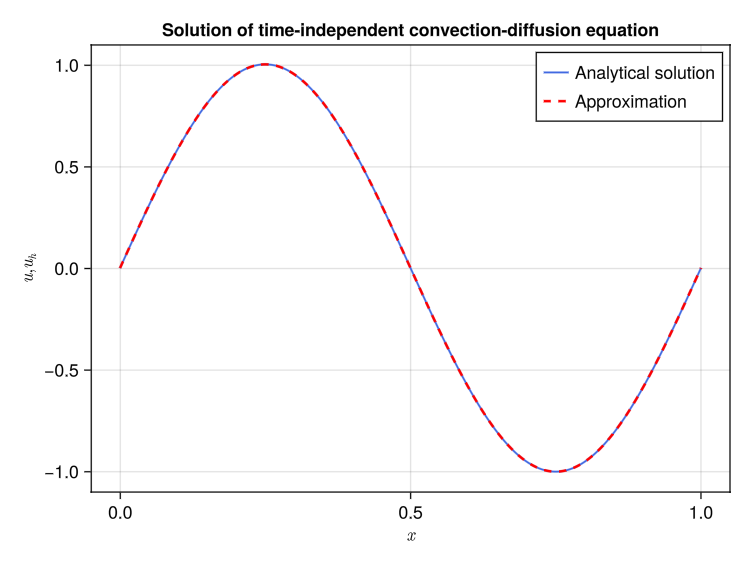

In [4]:
# Solution field for the time-independent problem
u_h = Forms.FormField(V⁰, zeros(Forms.get_num_basis(V⁰)), "u_h")

# Set boundary values
u_h.coefficients[1] = u_0
u_h.coefficients[end] = u_L

# Solve for the unknown coefficients
u_h.coefficients[2:(end - 1)] = K \ (F - u_0 * F_0 - u_L * F_L)

# Compute the L2 norm of the error
error = Analysis.L2_norm(u_analytical - u_h, dΩ)
println("L2 norm of error for time-independent problem: $(error)")

# Helper function to easily evaluate our solution
function evaluate_solution(u_h)
    geometry = Forms.get_geometry(u_h)
    num_elements = Geometry.get_num_elements(geometry)
    xi = Points.TensorProductPoints((LinRange(0.0, 1.0, 25),))

    all_x = Vector{Float64}(undef, 25 * num_elements)
    all_u = Vector{Float64}(undef, 25 * num_elements)
    
    for element_id in 1:num_elements
        form_eval, _ = Forms.evaluate(u_h, element_id, xi)
        x = Geometry.evaluate(geometry, element_id, xi)

        all_x[((element_id - 1) * 25 + 1):((element_id) * 25)] = x[:]
        all_u[((element_id - 1) * 25 + 1):((element_id) * 25)] = form_eval[1]
    end

    return all_x, all_u
end

# Evaluate and plot analytical solution and approximation
xe_analytical, ue_analytical = evaluate_solution(u_analytical)
xe_h, ue_h = evaluate_solution(u_h)

GLMakie.activate!(inline=true)
fig = Figure(size=(600, 450))

ax = Axis(
    fig[1, 1], 
    title="Solution of time-independent convection-diffusion equation",
    xlabel=L"x", 
    ylabel=L"u, u_h"
)

p1 = lines!(
    ax,
    xe_analytical, 
    ue_analytical; 
    color=:royalblue,
    linewidth=1.5
)

p2 = lines!(
    ax,
    xe_h, 
    ue_h; 
    color=:red, 
    linewidth=2,
    linestyle=:dash
)

axislegend(ax, [p1, p2], ["Analytical solution", "Approximation"])

save("Convection-diffusion_1D.png", fig)
println("Solution of time-independent problem saved as Convection-diffusion_1D.png")
display(fig);

## Solving the time-dependent problem

Finally, we use the explicit midpoint time integration scheme to solve the time-dependent problem given by
$$\mathbf{M} \frac{d\mathbf{C}}{dt} + \mathbf{KC} = \mathbf{F} - u_0 \mathbf{F}^{b,0} - u_L \mathbf{F}^{b,L}.$$

In [5]:
# Time step size
dt = 0.0005

# Number of time steps
num_time_steps = 1001

# Encode the ODE information for the time integrator
import LinearSolve as LS
prob = LS.LinearProblem(M, zeros(Forms.get_num_basis(V⁰)-2))
linsolve = LS.init(prob)

function convection_diffusion_solver(output, C::Vector{Float64}, t::Float64)
    linsolve.b = (-K * C + F - u_0 * F_0 - u_L * F_L)
    output .= LS.solve!(linsolve)
    return output
end
convection_diffusion = TimeIntegrators.define_explicit_ode(convection_diffusion_solver)

# Use explicit midpoint scheme
scheme = TimeIntegrators.EXPLICIT_MIDPOINT

# Project the initial profile onto our form space and enforce the boundary conditions
u_hi = Assemblers.solve_L2_projection(V⁰, g, dΩ)
u_hi.coefficients[1] = u_0
u_hi.coefficients[end] = u_L

# Initialise the time scheme
u_h_n = TimeIntegrators.initialise_scheme(u_hi.coefficients[2:(end - 1)], scheme)

# Use Printf to print the time in our animation
using Printf
time = Observable(dt)

# Perform time integration
ue_h = lift(time) do t
    TimeIntegrators.time_integrate!(u_h_n, convection_diffusion, t, dt)

    u_hi.coefficients[2:(end - 1)] = TimeIntegrators.get_solution(u_h_n)

    _, all_u = evaluate_solution(u_hi)

    return all_u
end

# Plot analytical solution and approximation
fig = Figure()

ax = Axis(
    fig[1, 1], 
    title="Solution of time-dependent convection-diffusion equation",
    xlabel=L"x", 
    ylabel=L"u, u_h"
)

p1 = lines!(
    ax,
    xe_analytical, 
    ue_analytical; 
    color=:royalblue,
    linewidth=1.5
)

p2 = lines!(
    ax,
    xe_h, 
    ue_h; 
    color=:red, 
    linewidth=2,
    linestyle=:dash
)

axislegend(ax, [p1, p2], ["Analytical steady-state solution", @lift("Approximation at t = $(@sprintf("%0.2f", round($time, digits = 2)))")])

record(
    fig,
    "Convection-diffusion_1D.mp4",
    LinRange(dt, dt*num_time_steps, num_time_steps);
    framerate=50,
) do t
    return time[] = t
end
println("Solution of time-dependent problem saved as Convection-diffusion_1D.mp4")

Solution of time-dependent problem saved as Convection-diffusion_1D.mp4
